# 📊 StudentScope: Student Lifestyle & Performance Explorer

### Data Science | Week 2 — Data Cleaning & Feature Engineering

**Author:** Dinesh Kumar Pulagalla  
**Dataset:** UCI Student Performance — Portuguese language course (`student-por.csv`)  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn  
**Continues from:** StudentScope Week 1 — Exploratory Data Analysis (EDA)

---

## 1. Week 2 Project Goal

Continue the same StudentScope project and the same UCI Student Performance dataset used in Week 1.

This notebook will:
1. Inspect categorical values and missing data.
2. Standardize categorical text using pandas string methods and mapping dictionaries.
3. Document and apply a missing-value strategy.
4. Create a new age-group feature.
5. Encode three categorical columns using `pd.get_dummies()`.
6. Repeat Week 1 group comparisons and check that the results remain consistent.
7. Save and reload `data/survey_clean.csv`.

## 2. Important note about this dataset

The Week 1 notebook found **649 rows, 33 original columns, and zero missing values**. The categorical values in this UCI file are already mostly consistent. Therefore, this notebook does not invent misspellings or missing responses.

To demonstrate category consolidation, we create a separate `Mjob_group` feature that groups the five original mother's-job categories into four broader groups. The original `Mjob` column is preserved. This is an analytical grouping, not a claim that the source data contained spelling errors.

**Week 1 baseline:** mean final grade by study-time category was 10.84, 12.09, 13.23, and 13.06 for categories 1–4 respectively.

## 3. Import libraries and load the same dataset used in Week 1

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# Use the same GitHub repository as the Week 1 project as a fallback source.
DATA_URL = "https://raw.githubusercontent.com/dk0009-pv/StudentScope-Student-Performance-Analysis/main/student-por.csv"

# In Google Colab, upload the same student-por.csv file used in Week 1.
try:
    from google.colab import files
    uploaded = files.upload()
    if uploaded:
        csv_file = next(iter(uploaded))
        df_raw = pd.read_csv(csv_file, sep=";")
        print("Loaded uploaded file:", csv_file)
    else:
        raise ValueError("No CSV file was uploaded.")
except ImportError:
    # In a local Jupyter environment, use a local CSV if available;
    # otherwise read the same CSV from the project's GitHub repository.
    local_csv = Path("student-por.csv")
    source = str(local_csv) if local_csv.exists() else DATA_URL
    df_raw = pd.read_csv(source, sep=";")
    print("Loaded dataset from:", source)

# Preserve the original data for before/after comparisons.
df_clean = df_raw.copy(deep=True)

print("Dataset shape:", df_raw.shape)
display(df_raw.head())

Saving student-por.csv to student-por.csv
Loaded uploaded file: student-por.csv
Dataset shape: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,0,yes,no,no,no,yes,yes,yes,no,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,no,yes,yes,yes,yes,yes,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,no,no,yes,yes,no,no,4,3,2,1,2,5,0,11,13,13


## 4. Inspect categorical values and missing data before cleaning

First inspect the actual values. The mapping and cleaning steps below are based on the categories present in this dataset.

In [2]:
TEXT_COLUMNS = [
    "school", "sex", "address", "internet",
    "famsize", "Mjob", "Fjob"
]

for column in TEXT_COLUMNS:
    print(f"\\n========== {column.upper()} — RAW VALUES ==========")
    print(sorted(df_raw[column].dropna().astype(str).unique()))

print("\\n========== MISSING VALUES BEFORE CLEANING ==========")
missing_before = df_raw.isna().sum().sort_values(ascending=False)
display(missing_before.to_frame("missing_before"))
print("Total missing cells:", int(df_raw.isna().sum().sum()))

\n========== SCHOOL — RAW VALUES ==========
['GP', 'MS']
\n========== SEX — RAW VALUES ==========
['F', 'M']
\n========== ADDRESS — RAW VALUES ==========
['R', 'U']
\n========== INTERNET — RAW VALUES ==========
['no', 'yes']
\n========== FAMSIZE — RAW VALUES ==========
['GT3', 'LE3']
\n========== MJOB — RAW VALUES ==========
['at_home', 'health', 'other', 'services', 'teacher']
\n========== FJOB — RAW VALUES ==========
['at_home', 'health', 'other', 'services', 'teacher']
\n========== MISSING VALUES BEFORE CLEANING ==========


,missing_before
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


Total missing cells: 0


## 5. Document the missing-value strategy

The Week 1 notebook found no missing values in the original 33 columns. We will still apply a documented strategy so the cleaning workflow also handles missing responses if they occur in a future version of the file.

- **Categorical columns:** fill missing responses with `unknown`. This preserves the row without guessing the student's answer.
- **Numeric age:** if any age is missing, fill it with the median age. The median is less sensitive to extreme values than the mean.
- **Other numeric columns:** leave unchanged in this exercise because the Week 1 source has no missing values in them. If missing values appear in those columns in another dataset version, investigate them before choosing an imputation strategy.
- **Rows:** do not drop records unnecessarily.

Because the current source has zero missing values, the fill operations below should not change any values.

## 6. Create `clean_categories(df)` using `.str` methods and mapping dictionaries

In [3]:
# Normalize category text to lowercase and remove leading/trailing or repeated spaces.
# These mappings also document the expected standardized values for selected fields.
CATEGORY_MAPPINGS = {
    "school": {"gp": "gp", "ms": "ms"},
    "sex": {"f": "f", "m": "m"},
    "address": {"u": "u", "r": "r"},
    "internet": {"yes": "yes", "no": "no"},
    "famsize": {"gt3": "gt3", "le3": "le3"}
}

# Consolidate mother's job categories into broader analytical groups.
# The original Mjob column remains unchanged apart from text normalization.
MJOB_GROUP_MAP = {
    "teacher": "professional",
    "health": "professional",
    "services": "services",
    "at_home": "home-based",
    "other": "other"
}

def clean_categories(frame):
    result = frame.copy(deep=True)

    for column in TEXT_COLUMNS:
        result[column] = (
            result[column]
            .astype("string")
            .str.strip()
            .str.lower()
            .str.replace(r"\s+", " ", regex=True)
        )

    # Apply documented mappings to standardize known categories.
    for column, mapping in CATEGORY_MAPPINGS.items():
        result[column] = result[column].replace(mapping)

    # Explicit missing-category policy.
    for column in TEXT_COLUMNS:
        result[column] = result[column].fillna("unknown")

    # Derived broader category for meaningful group comparison.
    result["Mjob_group"] = (
        result["Mjob"].map(MJOB_GROUP_MAP).fillna("unknown")
    )

    return result

df_clean = clean_categories(df_raw)

print("Category cleaning completed.")
display(df_clean[["Mjob", "Mjob_group"]].head(10))

Category cleaning completed.


,Mjob,Mjob_group
0,at_home,home-based
1,at_home,home-based
2,at_home,home-based
3,health,professional
4,other,other
5,services,services
6,other,other
7,other,other
8,services,services
9,other,other


## 7. Before/after unique-category comparison

The original `Mjob` column has five categories. The derived `Mjob_group` combines `teacher` and `health` into `professional`, producing four broader categories. This is category consolidation for analysis; the original column is retained.

,category_column,unique_values
0,Original Mjob,5
1,Grouped Mjob_group,4


Unique categories before grouping: 5
Unique categories after grouping:  4


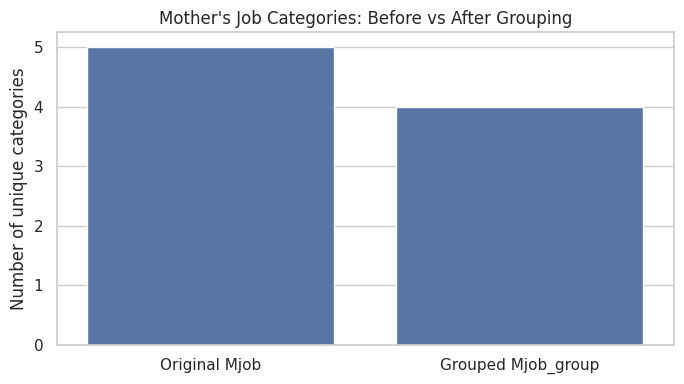

In [4]:
before_unique = df_raw["Mjob"].nunique(dropna=False)
after_unique = df_clean["Mjob_group"].nunique(dropna=False)

category_comparison = pd.DataFrame({
    "category_column": ["Original Mjob", "Grouped Mjob_group"],
    "unique_values": [before_unique, after_unique]
})
display(category_comparison)
print(f"Unique categories before grouping: {before_unique}")
print(f"Unique categories after grouping:  {after_unique}")

plt.figure(figsize=(7, 4))
sns.barplot(data=category_comparison, x="category_column", y="unique_values")
plt.title("Mother's Job Categories: Before vs After Grouping")
plt.xlabel("")
plt.ylabel("Number of unique categories")
plt.tight_layout()
plt.show()

## 8. Handle missing values and verify the selected columns

In [5]:
# Fill missing age values with the median only if missing values exist.
if df_clean["age"].isna().any():
    df_clean["age"] = df_clean["age"].fillna(df_clean["age"].median())

SELECTED_CLEAN_COLUMNS = [
    "school", "sex", "address", "internet", "famsize",
    "Mjob", "Fjob", "Mjob_group", "age", "G3"
]

missing_after = df_clean[SELECTED_CLEAN_COLUMNS].isna().sum()
display(missing_after.to_frame("missing_after"))

print("Missing values in selected cleaned columns:",
      int(missing_after.sum()))
print("Total missing cells in full cleaned dataset:",
      int(df_clean.isna().sum().sum()))

,missing_after
school,0
sex,0
address,0
internet,0
famsize,0
Mjob,0
Fjob,0
Mjob_group,0
age,0
G3,0


Missing values in selected cleaned columns: 0
Total missing cells in full cleaned dataset: 0


## 9. Create a bucketed feature using `pd.cut()`

Create `AgeGroup` from the continuous `age` column:
- Teen (15–17)
- Young Adult (18–20)
- Adult (21+)

In [6]:
AGE_BINS = [0, 17, 20, np.inf]
AGE_LABELS = ["Teen (15-17)", "Young Adult (18-20)", "Adult (21+)"]

df_clean["AgeGroup"] = pd.cut(
    df_clean["age"],
    bins=AGE_BINS,
    labels=AGE_LABELS,
    right=True
)

display(df_clean[["age", "AgeGroup"]].head(10))
display(df_clean["AgeGroup"].value_counts(dropna=False).to_frame("student_count"))

# Validate that all records received one of the expected age labels.
actual_age_groups = set(df_clean["AgeGroup"].dropna().astype(str).unique())
assert actual_age_groups.issubset(set(AGE_LABELS))
assert df_clean["AgeGroup"].notna().all(), "Some records have no age group."
print("PASS: AgeGroup contains only the expected labels.")

,age,AgeGroup
0,18,Young Adult (18-20)
1,17,Teen (15-17)
2,15,Teen (15-17)
3,15,Teen (15-17)
4,16,Teen (15-17)
5,16,Teen (15-17)
6,16,Teen (15-17)
7,17,Teen (15-17)
8,15,Teen (15-17)
9,15,Teen (15-17)


,student_count
AgeGroup,
Teen (15-17),468
Young Adult (18-20),178
Adult (21+),3


PASS: AgeGroup contains only the expected labels.


## 10. Encode 2–3 categorical columns using `pd.get_dummies()`

Encode `school`, `sex`, and `address`. Keep `df_clean` unchanged so we can still use the original category columns for group comparisons.

In [7]:
ENCODE_COLUMNS = ["school", "sex", "address"]

df_encoded = pd.get_dummies(
    df_clean,
    columns=ENCODE_COLUMNS,
    dtype=int
)

dummy_columns = [
    column for column in df_encoded.columns
    if column.startswith(("school_", "sex_", "address_"))
]

print("Cleaned data shape:", df_clean.shape)
print("One-hot encoded data shape:", df_encoded.shape)
print("New dummy columns:", dummy_columns)
display(df_encoded[dummy_columns].head())

Cleaned data shape: (649, 35)
One-hot encoded data shape: (649, 38)
New dummy columns: ['school_gp', 'school_ms', 'sex_f', 'sex_m', 'address_r', 'address_u']


,school_gp,school_ms,sex_f,sex_m,address_r,address_u
0,1,0,1,0,0,1
1,1,0,1,0,0,1
2,1,0,1,0,0,1
3,1,0,1,0,0,1
4,1,0,1,0,0,1


## 11. Repeat Week 1 group comparisons on the cleaned data

Week 1 compared final grade (`G3`) by `studytime`. Repeat the same comparison and verify that the cleaning process has not changed the group counts or grade averages.

In [8]:
week1_study = df_raw.groupby("studytime")["G3"].agg(["count", "mean", "median"])
week2_study = df_clean.groupby("studytime")["G3"].agg(["count", "mean", "median"])

comparison = week1_study.join(
    week2_study,
    lsuffix="_week1",
    rsuffix="_week2"
)
comparison["mean_difference"] = (
    comparison["mean_week2"] - comparison["mean_week1"]
)

display(comparison.round(3))

# The cleaning process should not alter studytime or G3.
assert comparison["count_week1"].equals(comparison["count_week2"])
assert np.allclose(comparison["mean_week1"], comparison["mean_week2"])
assert np.allclose(comparison["median_week1"], comparison["median_week2"])
print("PASS: Week 1 and Week 2 study-time group counts and grade statistics match.")

print("\\nAverage final grade by school:")
display(df_clean.groupby("school")["G3"].agg(["count", "mean"]).round(2))

print("\\nAverage final grade by AgeGroup:")
display(df_clean.groupby("AgeGroup", observed=False)["G3"].agg(["count", "mean"]).round(2))

,count_week1,mean_week1,median_week1,count_week2,mean_week2,median_week2,mean_difference
studytime,,,,,,,
1,212,10.844,11.0,212,10.844,11.0,0.0
2,305,12.092,12.0,305,12.092,12.0,0.0
3,97,13.227,13.0,97,13.227,13.0,0.0
4,35,13.057,13.0,35,13.057,13.0,0.0


PASS: Week 1 and Week 2 study-time group counts and grade statistics match.
\nAverage final grade by school:


,count,mean
school,,
gp,423,12.58
ms,226,10.65


\nAverage final grade by AgeGroup:


,count,mean
AgeGroup,,
Teen (15-17),468,12.13
Young Adult (18-20),178,11.38
Adult (21+),3,9.00


## 12. Visualize average final grade by age group

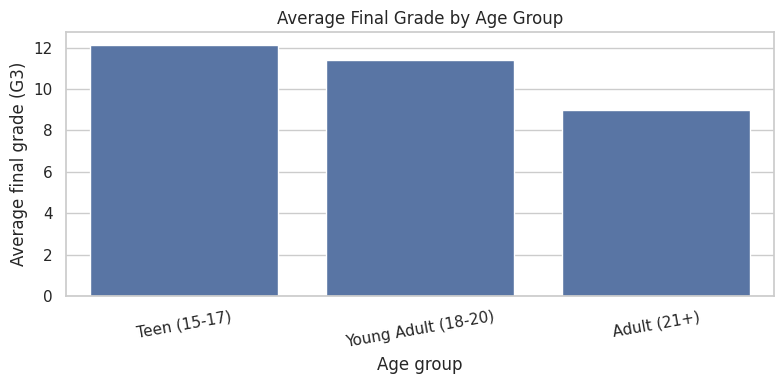

In [9]:
plt.figure(figsize=(8, 4))
sns.barplot(data=df_clean, x="AgeGroup", y="G3", errorbar=None)
plt.title("Average Final Grade by Age Group")
plt.xlabel("Age group")
plt.ylabel("Average final grade (G3)")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

## 13. Stretch goal — allow-list and data-quality tests

In [10]:
def validate_cleaned_data(raw, cleaned, encoded):
    allowed_mjob_groups = set(MJOB_GROUP_MAP.values()) | {"unknown"}
    allowed_age_groups = set(AGE_LABELS)

    assert set(cleaned["Mjob_group"].unique()).issubset(allowed_mjob_groups)
    assert set(cleaned["AgeGroup"].dropna().astype(str).unique()).issubset(allowed_age_groups)
    assert cleaned["AgeGroup"].notna().all()

    assert len(raw) == len(cleaned) == len(encoded)
    assert cleaned[SELECTED_CLEAN_COLUMNS].isna().sum().sum() == 0
    assert all(column in encoded.columns for column in dummy_columns)
    assert cleaned["G3"].equals(raw["G3"])
    assert cleaned["studytime"].equals(raw["studytime"])

    return True

assert validate_cleaned_data(df_raw, df_clean, df_encoded)
print("PASS: Mjob_group allow-list")
print("PASS: AgeGroup allow-list")
print("PASS: row counts and selected-column missing values")
print("PASS: one-hot encoded columns")
print("PASS: original G3 and studytime values preserved")

PASS: Mjob_group allow-list
PASS: AgeGroup allow-list
PASS: row counts and selected-column missing values
PASS: one-hot encoded columns
PASS: original G3 and studytime values preserved


## 14. Save `data/survey_clean.csv` and reload it

In [11]:
DATA_DIR = Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

CLEAN_PATH = DATA_DIR / "survey_clean.csv"
ENCODED_PATH = DATA_DIR / "survey_encoded.csv"

# Required deliverable: cleaned data with readable category columns.
df_clean.to_csv(CLEAN_PATH, index=False)

# Additional output: one-hot encoded data for further modelling/analysis.
df_encoded.to_csv(ENCODED_PATH, index=False)

# Reload the required CSV and verify its structure.
df_check = pd.read_csv(CLEAN_PATH)

print("Saved cleaned file:", CLEAN_PATH)
print("Saved encoded file:", ENCODED_PATH)
print("Reloaded shape:", df_check.shape)
print("Expected shape:", df_clean.shape)
print("Reloaded columns match:", df_check.columns.tolist() == df_clean.columns.tolist())
print("Missing values in selected cleaned columns:",
      int(df_check[SELECTED_CLEAN_COLUMNS].isna().sum().sum()))

assert df_check.shape == df_clean.shape
assert df_check.columns.tolist() == df_clean.columns.tolist()
assert df_check[SELECTED_CLEAN_COLUMNS].isna().sum().sum() == 0
display(df_check.head())

Saved cleaned file: data/survey_clean.csv
Saved encoded file: data/survey_encoded.csv
Reloaded shape: (649, 35)
Expected shape: (649, 35)
Reloaded columns match: True
Missing values in selected cleaned columns: 0


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,Mjob_group,AgeGroup
0,gp,f,18,u,gt3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11,home-based,Young Adult (18-20)
1,gp,f,17,u,gt3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,2,9,11,11,home-based,Teen (15-17)
2,gp,f,15,u,le3,T,1,1,at_home,other,other,mother,1,2,0,yes,no,no,no,yes,yes,yes,no,4,3,2,2,3,3,6,12,13,12,home-based,Teen (15-17)
3,gp,f,15,u,gt3,T,4,2,health,services,home,mother,1,3,0,no,yes,no,yes,yes,yes,yes,yes,3,2,2,1,1,5,0,14,14,14,professional,Teen (15-17)
4,gp,f,16,u,gt3,T,3,3,other,other,home,father,1,2,0,no,yes,no,no,yes,yes,no,no,4,3,2,1,2,5,0,11,13,13,other,Teen (15-17)


## 15. Key findings and conclusion

After running all cells, record your findings from the outputs:

1. **Category consolidation:** `Mjob` has five original categories; the derived `Mjob_group` has four broader categories.
2. **Missing values:** Week 1 found zero missing values in the source dataset. The selected cleaned columns should also contain zero missing values.
3. **Feature engineering:** `AgeGroup` divides students into Teen, Young Adult, and Adult categories.
4. **Encoding:** `school`, `sex`, and `address` are represented by one-hot encoded columns in `df_encoded`.
5. **Week 1 comparison:** The average final grades by study-time category should remain unchanged because the cleaning steps do not modify `studytime` or `G3`.

### Limitations

- This dataset represents students from two Portuguese schools and should not be treated as representative of all students.
- The category consolidation is a derived analytical grouping, not correction of source spelling errors.
- Group averages describe associations and do not prove cause and effect.

